<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/hough_esmerkezli_cember.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

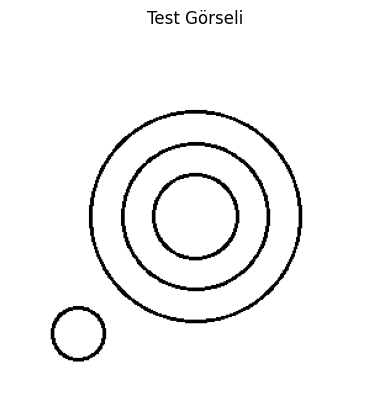

True

In [2]:
resim = np.full((300, 300, 3), 255, dtype=np.uint8)

# Aynı merkezde üç farklı yarıçap
merkez = (150, 150)

cv2.circle(resim, merkez, 34, (0, 0, 0), 2)
cv2.circle(resim, merkez, 59, (0, 0, 0), 2)
cv2.circle(resim, merkez, 85, (0, 0, 0), 2)

# Eş merkezli olmayan ayrı bir çember
cv2.circle(resim, (55, 245), 21, (0, 0, 0), 2)

plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Test Görseli")
plt.axis("off")
plt.show()

cv2.imwrite("test_gorseli.png", resim)

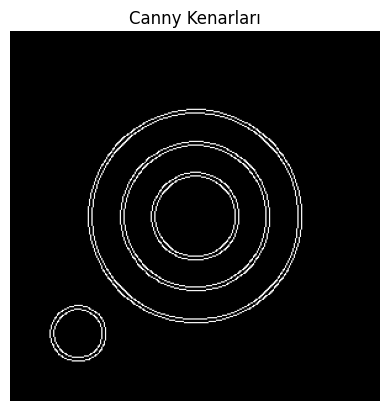

In [3]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

kenarlar = cv2.Canny(gri, 60, 150)

plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarları")
plt.axis("off")
plt.show()

In [4]:
# Açılar: 0, 10, 20, ... 350 derece
acilar = np.deg2rad(np.arange(0, 360, 10))

sin_tablosu = np.sin(acilar)
cos_tablosu = np.cos(acilar)

# Aranacak yarıçaplar
yaricaplar = np.arange(25, 98, 2)

print("Açı sayısı:", len(acilar))
print("Yarıçap sayısı:", len(yaricaplar))

Açı sayısı: 36
Yarıçap sayısı: 37


In [5]:
yukseklik, genislik = kenarlar.shape

oylama = np.zeros(
    (len(yaricaplar), yukseklik, genislik),
    dtype=np.int32
)

print("3D oylama matrisi:", oylama.shape)

3D oylama matrisi: (37, 300, 300)


In [6]:
# Kenar noktalarını bul
ys, xs = np.where(kenarlar > 0)

# Her yarıçap için
for i, r in enumerate(yaricaplar):

    # Her açı için
    for t in range(len(acilar)):

        # Olası merkezler
        a = np.rint(
            xs - r * cos_tablosu[t]
        ).astype(int)

        b = np.rint(
            ys - r * sin_tablosu[t]
        ).astype(int)

        # Görüntü sınırlarının içindeki merkezler
        gecerli = (
            (a >= 0) & (a < genislik) &
            (b >= 0) & (b < yukseklik)
        )

        # 3D matriste oy verme
        np.add.at(
            oylama[i],
            (b[gecerli], a[gecerli]),
            1
        )

print("Oylama tamamlandı!")
print("En yüksek oy:", oylama.max())

Oylama tamamlandı!
En yüksek oy: 28


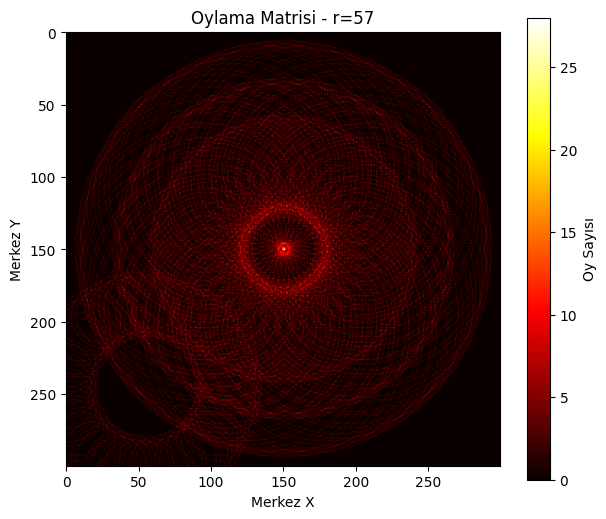

In [7]:
# En yüksek oya sahip yarıçap katmanını bul
r_indeks, _, _ = np.unravel_index(
    np.argmax(oylama),
    oylama.shape
)

plt.figure(figsize=(7, 6))

plt.imshow(oylama[r_indeks], cmap="hot")

plt.title(
    f"Oylama Matrisi - r={yaricaplar[r_indeks]}"
)

plt.xlabel("Merkez X")
plt.ylabel("Merkez Y")

plt.colorbar(label="Oy Sayısı")

plt.savefig("oylama_kesiti.png", dpi=200)
plt.show()

# Üç boyutlu matrisi kaydet
np.save("oylama_3d.npy", oylama)

In [8]:
# Oylama matrisinin kopyasını oluştur
kopya = oylama.copy()

yaricap_indeksleri = []
yaricap_oylari = []

# Her merkezde en güçlü 3 farklı yarıçapı ara
for k in range(3):

    # En çok oy alan yarıçap
    indeks = np.argmax(kopya, axis=0)

    oy = np.take_along_axis(
        kopya,
        indeks[None, :, :],
        axis=0
    )[0]

    yaricap_indeksleri.append(indeks)
    yaricap_oylari.append(oy)

    # Aynı çemberin yakın yarıçaplarını tekrar sayma
    secilen_r = yaricaplar[indeks]

    yakin = (
        np.abs(
            yaricaplar[:, None, None] -
            secilen_r[None, :, :]
        ) < 12
    )

    kopya[yakin] = 0

yaricap_indeksleri = np.stack(yaricap_indeksleri)
yaricap_oylari = np.stack(yaricap_oylari)

# Bir yarıçapın kabul edilmesi için gereken oy
min_oy = max(10, int(oylama.max() * 0.38))

# Her merkezde kaç farklı yarıçap yeterli oy almış?
gecerli_yaricap = yaricap_oylari >= min_oy

yaricap_sayisi = np.sum(
    gecerli_yaricap,
    axis=0
)

# Aynı merkezin farklı yarıçaplarından gelen oyları topla
puan = np.sum(
    np.where(gecerli_yaricap, yaricap_oylari, 0),
    axis=0
)

# En az iki farklı yarıçap gerekli
puan[yaricap_sayisi < 2] = 0

print("En yüksek eş merkezlilik puanı:", puan.max())

En yüksek eş merkezlilik puanı: 73


In [10]:
aday_puan = puan.copy()

gruplar = []

min_puan = max(25, int(puan.max() * 0.60))

# En fazla 3 eş merkezli grup ara
for _ in range(3):

    y, x = np.unravel_index(
        np.argmax(aday_puan),
        aday_puan.shape
    )

    if aday_puan[y, x] < min_puan:
        break

    bulunan_yaricaplar = []

    # Bu merkez için güçlü yarıçapları al
    for k in range(3):

        oy = int(yaricap_oylari[k, y, x])

        if oy >= min_oy:
            indeks = yaricap_indeksleri[k, y, x]
            r = int(yaricaplar[indeks])

            bulunan_yaricaplar.append(r)

    gruplar.append((int(x), int(y), bulunan_yaricaplar))

    # Aynı merkezin komşu adaylarını tekrar seçme
    aday_puan[
        max(0, y-25):min(yukseklik, y+26),
        max(0, x-25):min(genislik, x+26)
    ] = 0

print("Bulunan eş merkezli gruplar:")

for x, y, rs in gruplar:
    print("Merkez:", (x, y), "Yarıçaplar:", rs)

Bulunan eş merkezli gruplar:
Merkez: (150, 150) Yarıçaplar: [57, 33, 83]


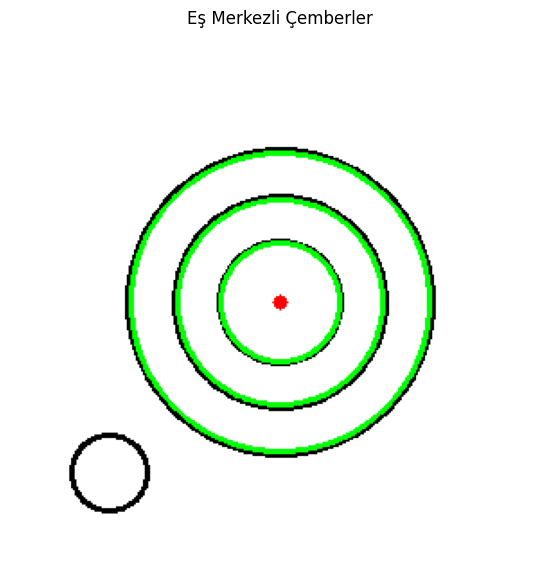

In [11]:
sonuc = resim.copy()

for x, y, rs in gruplar:

    # Aynı merkezdeki bütün çemberleri çiz
    for r in rs:
        cv2.circle(
            sonuc,
            (x, y),
            r,
            (0, 255, 0),
            2
        )

    # Ortak merkezi kırmızı göster
    cv2.circle(
        sonuc,
        (x, y),
        4,
        (0, 0, 255),
        -1
    )

plt.figure(figsize=(7, 7))

plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Eş Merkezli Çemberler")
plt.axis("off")

plt.savefig("es_merkezli_sonuc.png", dpi=200)
plt.show()

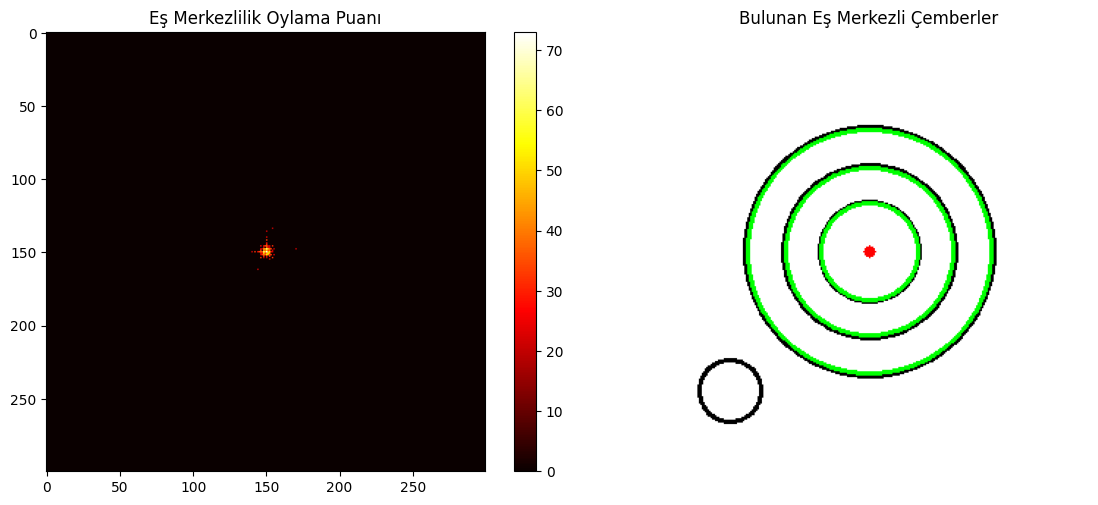

In [12]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(puan, cmap="hot")
plt.title("Eş Merkezlilik Oylama Puanı")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Bulunan Eş Merkezli Çemberler")
plt.axis("off")

plt.tight_layout()
plt.savefig("odev5_karsilastirma.png", dpi=200)
plt.show()